# 05 - External validation of the GSE120584 ncRNA signature

**Question:** does what we learned on GSE120584 (Japanese serum, 3D-Gene microarray) hold up in
independent cohorts measured with other technologies?

| Dataset | Tissue | Technology | Groups |
|---|---|---|---|
| GSE215789 | plasma, serum (same people) | small RNA-seq | AD / MCI / NC |
| GSE46579 | whole blood | small RNA-seq (older miRBase names) | AD / NC |
| GSE305625 | plasma, CSF (same donors) | TaqMan qPCR, 64 pre-chosen miRNAs | AD / NC |
| GSE157239 | brain (temporal cortex) | Affymetrix miRNA 4.1 | AD / NC (n=16) |

**Why the locked model from notebook 04 is not applied directly.** It uses 3D-Gene log2 values, APOE4
and an array-specific quality covariate (`detect_rate`). None of these exist on the external
platforms (values are on different scales, and no external cohort has APOE4). Pushing other platforms'
numbers through it would test the platform mismatch, not the biology.

**What is transferred instead (fully locked, nothing refit on external data):**
1. **Signature** = the 263 miRNAs that differ AD vs NC in the *training split*, after adjusting for age,
   sex, APOE4 and sample quality (FDR < 0.05), each with its training direction (up/down in AD).
2. **Locked score** per person = average of (direction x within-cohort z-score) over the signature
   miRNAs detected in that cohort.
3. **Top-10 ncRNAs** from notebook 03.

Tests: (A) coverage/detection, (B) direction concordance, (C) locked-score AUC,
(D) within-cohort refit as a "is there any AD signal here?" reference, (E) MCI in GSE215789.

In [1]:
import sys, json, warnings
sys.path.append("../src")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import roc_auc_score

from utils import ROOT, FIGURES, SEED
from modeling import bootstrap_auc_ci
from external import (PLATFORM, training_signature, prepare, signature_score, perm_auc_p,
                      ad_nc_effects, refit_cv_auc)

TAB = ROOT / "results" / "tables"
FIG = FIGURES / "05_external"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
def savefig(n): plt.savefig(FIG / f"{n}.png", dpi=150, bbox_inches="tight")

sig = training_signature()
top10 = json.load(open(ROOT / "results" / "models" / "04_locked_config.json"))["top10"]
train_all = pd.read_csv(TAB / "01_eda_AD_vs_NC_univariate.csv").set_index("miRNA")
print(f"Training signature: {len(sig)} miRNAs ({(sig.sign > 0).sum()} up in AD, {(sig.sign < 0).sum()} down)")

data = {n: prepare(n) for n in PLATFORM}

Training signature: 263 miRNAs (216 up in AD, 47 down)


## A. Coverage: are the training miRNAs even measured / detected externally?

"Detected" rules (fixed before looking at labels): RNA-seq >= 5 reads in >= 50% of samples;
qPCR <= 20% missing; brain array log2 signal > 3 in >= 50% of samples.

In [2]:
rows = []
for n, (Xl, c, det) in data.items():
    rows.append({"dataset": n, "platform": PLATFORM[n], "n": len(c),
                 "AD": (c.diagnosis == "AD").sum(), "MCI": (c.diagnosis == "MCI").sum(), "NC": (c.diagnosis == "NC").sum(),
                 "miRNAs_measured": Xl.shape[1], "miRNAs_detected": len(det),
                 "signature_measured": sum(m in Xl.columns for m in sig.index),
                 "signature_detected": sum(m in det for m in sig.index),
                 "top10_measured": sum(t in Xl.columns for t in top10),
                 "top10_detected": sum(t in det for t in top10)})
cover = pd.DataFrame(rows).set_index("dataset")
cover.to_csv(TAB / "05_external_coverage.csv")
cover

,platform,n,AD,MCI,NC,miRNAs_measured,miRNAs_detected,signature_measured,signature_detected,top10_measured,top10_detected
dataset,,,,,,,,,,,
GSE215789_plasma,seq_counts,105,23,61,21,2743,287,254,25,10,0
GSE215789_serum,seq_counts,112,28,63,21,2743,267,254,21,10,0
GSE46579_blood,seq_normalized,70,48,0,22,417,344,21,18,0,0
GSE305625_plasma,qpcr,145,71,0,74,60,60,2,2,0,0
GSE305625_csf,qpcr,143,68,0,75,60,60,2,2,0,0
GSE157239_brain,array_log2,16,8,0,8,2578,503,259,49,10,3


In [3]:
# Top-10 detection rate in each cohort (fraction of samples with signal)
det_rate = {}
for n, (Xl, c, det) in data.items():
    from utils import load_dataset
    X, _ = load_dataset(n)
    if PLATFORM[n].startswith("seq"):
        det_rate[n] = {t: (X[t] >= 5).mean() if t in X else np.nan for t in top10}
    elif PLATFORM[n] == "array_log2":
        det_rate[n] = {t: (X[t] > 3).mean() if t in X else np.nan for t in top10}
    else:
        det_rate[n] = {t: X[t].notna().mean() if t in X else np.nan for t in top10}
top10_det = pd.DataFrame(det_rate)
top10_det.round(2)

,GSE215789_plasma,GSE215789_serum,GSE46579_blood,GSE305625_plasma,GSE305625_csf,GSE157239_brain
hsa-miR-128-1-5p,0.34,0.14,NaN,NaN,NaN,0.81
hsa-miR-3917,0.00,0.00,NaN,NaN,NaN,0.00
hsa-miR-4667-5p,0.33,0.09,NaN,NaN,NaN,0.19
hsa-miR-1471,0.00,0.00,NaN,NaN,NaN,0.00
hsa-miR-6861-5p,0.06,0.02,NaN,NaN,NaN,0.75
hsa-miR-3122,0.02,0.02,NaN,NaN,NaN,0.00
hsa-miR-6743-5p,0.00,0.00,NaN,NaN,NaN,1.00
hsa-miR-3689d,0.00,0.00,NaN,NaN,NaN,0.00
hsa-miR-6840-3p,0.00,0.00,NaN,NaN,NaN,0.06
hsa-miR-6784-5p,0.01,0.00,NaN,NaN,NaN,0.06


**Reading A.** The training signature is dominated by high-numbered miRNAs (miR-4xxx, miR-6xxx) that
the 3D-Gene array reports but small RNA-seq barely sees, and the qPCR panel (chosen from the literature)
contains almost none of them. The top-10 are measured in GSE215789 and the brain set but essentially
never detected by RNA-seq. This alone limits how far the GSE120584 findings can be validated.

## B. Direction concordance (signature miRNAs detected externally)

In [4]:
conc_rows, eff_tables = [], {}
for n, (Xl, c, det) in data.items():
    m = c.diagnosis.isin(["AD", "NC"]); y = (c.diagnosis[m] == "AD").astype(int)
    eff = ad_nc_effects(Xl.loc[m, det], y)
    eff_tables[n] = eff
    s = [x for x in sig.index if x in det]
    if not s:
        continue
    same = np.sign(eff.loc[s, "ext_diff"]) == sig.loc[s, "sign"]
    nom = eff.loc[s, "ext_p"] < 0.05
    shared = [x for x in train_all.index if x in det]   # all 817 training-tested miRNAs detected here
    rho, rho_p = stats.spearmanr(train_all.loc[shared, "beta_adj_q"], eff.loc[shared, "ext_diff"])
    conc_rows.append({"dataset": n, "n_sig_detected": len(s), "same_direction": int(same.sum()),
                      "concordance": same.mean(), "binom_p": stats.binomtest(int(same.sum()), len(s)).pvalue,
                      "n_nominal_p<0.05": int(nom.sum()), "same_dir_among_nominal": int((same & nom).sum()),
                      "n_shared_all": len(shared), "effect_spearman": rho, "effect_spearman_p": rho_p})
conc = pd.DataFrame(conc_rows).set_index("dataset")
conc.to_csv(TAB / "05_external_concordance.csv")
conc.round(3)

,n_sig_detected,same_direction,concordance,binom_p,n_nominal_p<0.05,same_dir_among_nominal,n_shared_all,effect_spearman,effect_spearman_p
dataset,,,,,,,,,
GSE215789_plasma,25,10,0.400,0.424,2,0,69,0.169,0.164
GSE215789_serum,21,7,0.333,0.189,0,0,65,0.106,0.400
GSE46579_blood,18,15,0.833,0.008,2,2,58,0.065,0.630
GSE305625_plasma,2,0,0.000,0.500,0,0,11,-0.355,0.285
GSE305625_csf,2,1,0.500,1.000,0,0,11,-0.427,0.190
GSE157239_brain,49,17,0.347,0.044,4,0,280,-0.166,0.005


Concordance = share of signature miRNAs whose AD-vs-NC direction matches training (50% = chance).
`effect_spearman` correlates training and external effects over *all* shared detected miRNAs.
Note: miRNAs are correlated with each other, so the binomial p-value is optimistic.

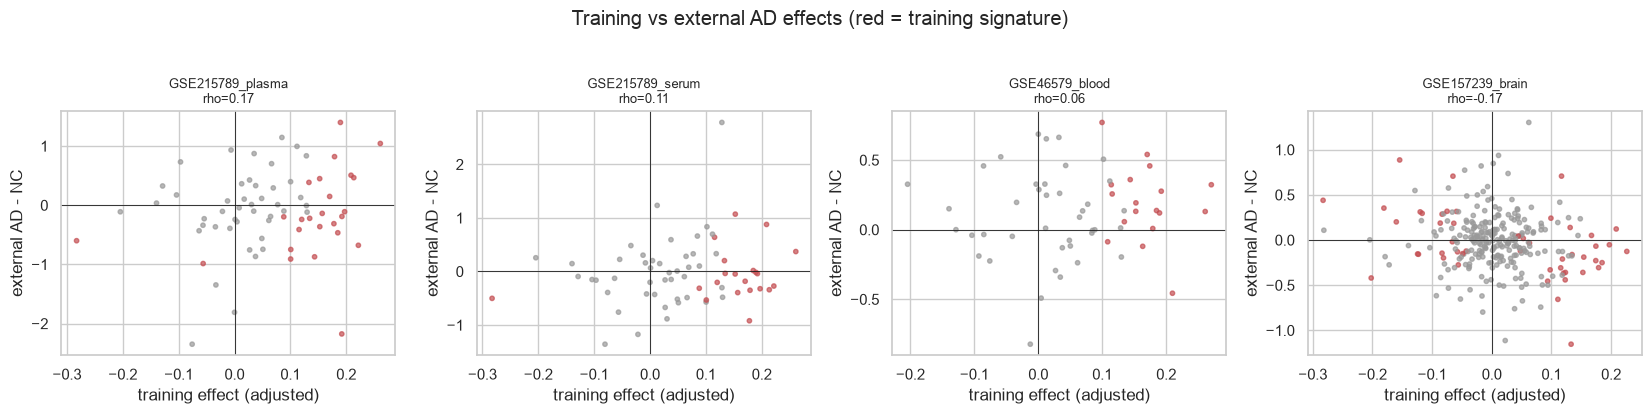

In [5]:
plot_sets = [n for n in conc.index if conc.loc[n, "n_shared_all"] >= 20]
fig, axes = plt.subplots(1, len(plot_sets), figsize=(4.2 * len(plot_sets), 4), squeeze=False)
for ax, n in zip(axes[0], plot_sets):
    eff = eff_tables[n]; shared = [x for x in train_all.index if x in eff.index]
    is_sig = [x in sig.index for x in shared]
    ax.scatter(train_all.loc[shared, "beta_adj_q"], eff.loc[shared, "ext_diff"], s=10,
               c=np.where(is_sig, "C3", "0.6"), alpha=.7)
    ax.axhline(0, c="k", lw=.6); ax.axvline(0, c="k", lw=.6)
    ax.set_title(f"{n}\nrho={conc.loc[n, 'effect_spearman']:.2f}", fontsize=9)
    ax.set_xlabel("training effect (adjusted)"); ax.set_ylabel("external AD - NC")
plt.suptitle("Training vs external AD effects (red = training signature)", y=1.03)
plt.tight_layout(); savefig("effect_concordance"); plt.show()

## C. Locked signature score (no refitting)

In [6]:
score_rows, scores = [], {}
for n, (Xl, c, det) in data.items():
    s = [x for x in sig.index if x in det]
    if len(s) < 5:
        score_rows.append({"dataset": n, "n_miRNAs_in_score": len(s), "note": "too few signature miRNAs"}); continue
    sc = signature_score(Xl[s], sig.loc[s, "sign"]); scores[n] = sc
    m = c.diagnosis.isin(["AD", "NC"]); y = (c.diagnosis[m] == "AD").astype(int); v = sc[m]
    lo, hi = bootstrap_auc_ci(y, v, n=2000)
    r = {"dataset": n, "n_miRNAs_in_score": len(s), "n_AD": int(y.sum()), "n_NC": int((1 - y).sum()),
         "AUC": roc_auc_score(y, v), "AUC_95CI": f"{lo:.2f}-{hi:.2f}", "perm_p_two_sided": perm_auc_p(y, v)}
    # Does the score add beyond age and sex where available?
    cc = c.loc[m]
    if cc.age.notna().all() and cc.sex.notna().all():
        Xc = pd.DataFrame({"const": 1.0, "score_z": (v - v.mean()) / v.std(), "age": cc.age,
                           "female": (cc.sex == "female").astype(int)})
        try:
            fit = sm.Logit(y, Xc).fit(disp=0)
            r["OR_per_SD_adj_age_sex"] = np.exp(fit.params["score_z"]); r["p_adj_age_sex"] = fit.pvalues["score_z"]
            r["AUC_age_sex_only"] = roc_auc_score(y, sm.Logit(y, Xc.drop(columns="score_z")).fit(disp=0).predict())
        except Exception as e:
            r["note"] = f"logit failed: {e}"
    score_rows.append(r)
score_res = pd.DataFrame(score_rows).set_index("dataset")
score_res.to_csv(TAB / "05_external_locked_score.csv")
score_res.round(3)

,n_miRNAs_in_score,n_AD,n_NC,AUC,AUC_95CI,perm_p_two_sided,OR_per_SD_adj_age_sex,p_adj_age_sex,AUC_age_sex_only,note
dataset,,,,,,,,,,
GSE215789_plasma,25,23.0,21.0,0.420,0.25-0.60,0.388,1.002,0.997,0.845,NaN
GSE215789_serum,21,28.0,21.0,0.468,0.30-0.64,0.718,0.973,0.948,0.866,NaN
GSE46579_blood,18,48.0,22.0,0.636,0.48-0.78,0.080,NaN,NaN,NaN,NaN
GSE305625_plasma,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,too few signature miRNAs
GSE305625_csf,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,too few signature miRNAs
GSE157239_brain,49,8.0,8.0,0.234,0.00-0.52,0.082,0.312,0.097,0.578,NaN


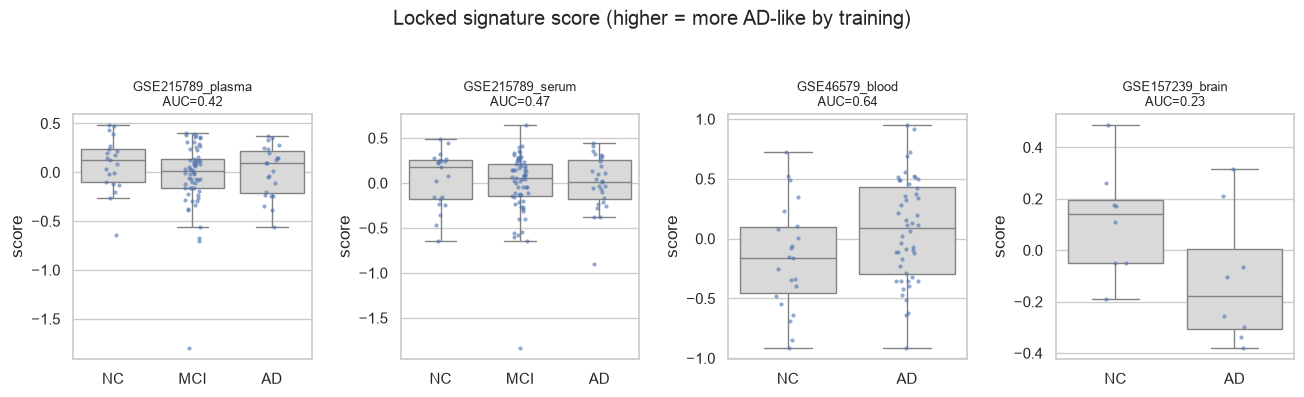

In [7]:
fig, axes = plt.subplots(1, len(scores), figsize=(3.3 * len(scores), 3.8), squeeze=False)
for ax, (n, sc) in zip(axes[0], scores.items()):
    c = data[n][1]; d = pd.DataFrame({"score": sc, "dx": c.diagnosis})
    order = [g for g in ["NC", "MCI", "AD"] if g in set(d.dx)]
    sns.boxplot(d, x="dx", y="score", order=order, ax=ax, color="0.85", fliersize=0)
    sns.stripplot(d, x="dx", y="score", order=order, ax=ax, s=3, alpha=.6)
    ax.set_title(f"{n}\nAUC={score_res.loc[n, 'AUC']:.2f}", fontsize=9); ax.set_xlabel("")
plt.suptitle("Locked signature score (higher = more AD-like by training)", y=1.04)
plt.tight_layout(); savefig("locked_score"); plt.show()

## D. Reference: is there an AD signal inside each external cohort at all?

Refit *within* each cohort (L2 logistic regression, repeated stratified 5-fold CV, 10 repeats):
- `all_detected`: all detected miRNAs (upper reference; shows the cohort itself is informative or not)
- `signature`: only the training-signature miRNAs detected there (features chosen on GSE120584)
- `random_null`: 100 random miRNA sets of the same size, giving the percentile of `signature`

If `signature` beats most random sets, the training-chosen miRNAs carry transferable information even
if the exact weights/directions do not transfer. If `age_sex` is available it is shown for context.

In [8]:
rng = np.random.default_rng(SEED)
refit_rows = []
for n, (Xl, c, det) in data.items():
    m = c.diagnosis.isin(["AD", "NC"]); y = (c.diagnosis[m] == "AD").astype(int)
    Xd = Xl.loc[m, det].fillna(Xl.loc[m, det].median())
    s = [x for x in sig.index if x in det]
    r = {"dataset": n, "n": len(y), "all_detected": refit_cv_auc(Xd, y)}
    cc = c.loc[m]
    if cc.age.notna().all():
        r["age_sex"] = refit_cv_auc(pd.DataFrame({"age": cc.age, "female": (cc.sex == "female").astype(int)}), y)
    if len(s) >= 5:
        r["n_signature"] = len(s)
        r["signature"] = refit_cv_auc(Xd[s], y)
        null = [refit_cv_auc(Xd[list(rng.choice(det, len(s), replace=False))], y, n_repeats=3) for _ in range(100)]
        r["random_null_median"] = float(np.median(null))
        r["signature_percentile_vs_random"] = float((np.array(null) < r["signature"]).mean() * 100)
    refit_rows.append(r)
refit = pd.DataFrame(refit_rows).set_index("dataset")
refit.to_csv(TAB / "05_external_refit.csv")
refit.round(3)

,n,all_detected,age_sex,n_signature,signature,random_null_median,signature_percentile_vs_random
dataset,,,,,,,
GSE215789_plasma,44,0.645,0.814,25.0,0.578,0.547,63.0
GSE215789_serum,49,0.606,0.842,21.0,0.450,0.569,8.0
GSE46579_blood,70,0.813,NaN,18.0,0.691,0.658,68.0
GSE305625_plasma,145,0.716,0.463,NaN,NaN,NaN,NaN
GSE305625_csf,143,0.623,0.508,NaN,NaN,NaN,NaN
GSE157239_brain,16,0.578,0.212,49.0,0.716,0.479,99.0


## E. MCI (GSE215789): does the locked score place MCI between NC and AD?

In [9]:
mci_rows = []
for n in ["GSE215789_plasma", "GSE215789_serum"]:
    if n not in scores: continue
    sc = scores[n]; dx = data[n][1].diagnosis
    for a, b in [("MCI", "NC"), ("AD", "NC"), ("AD", "MCI")]:
        m = dx.isin([a, b]); y = (dx[m] == a).astype(int)
        lo, hi = bootstrap_auc_ci(y, sc[m], n=2000)
        mci_rows.append({"dataset": n, "comparison": f"{a} vs {b}", "n": int(m.sum()),
                         "AUC": roc_auc_score(y, sc[m]), "AUC_95CI": f"{lo:.2f}-{hi:.2f}",
                         "perm_p_two_sided": perm_auc_p(y, sc[m])})
    rho, p = stats.spearmanr(dx.map({"NC": 0, "MCI": 1, "AD": 2}), sc)
    mci_rows.append({"dataset": n, "comparison": "trend NC<MCI<AD (Spearman rho)", "n": len(dx), "AUC": rho, "perm_p_two_sided": p})
mci = pd.DataFrame(mci_rows)
mci.to_csv(TAB / "05_external_mci.csv", index=False)
mci.round(3)

,dataset,comparison,n,AUC,AUC_95CI,perm_p_two_sided
0,GSE215789_plasma,MCI vs NC,82,0.389,0.24-0.53,0.118
1,GSE215789_plasma,AD vs NC,44,0.420,0.25-0.60,0.388
2,GSE215789_plasma,AD vs MCI,84,0.528,0.38-0.67,0.692
3,GSE215789_plasma,trend NC<MCI<AD (Spearman rho),105,-0.086,NaN,0.381
4,GSE215789_serum,MCI vs NC,84,0.454,0.29-0.61,0.546
5,GSE215789_serum,AD vs NC,49,0.468,0.30-0.64,0.718
6,GSE215789_serum,AD vs MCI,91,0.505,0.37-0.64,0.944
7,GSE215789_serum,trend NC<MCI<AD (Spearman rho),112,-0.037,NaN,0.698


## F. Summary

The cell below assembles one table. Interpretation is written in section G after looking at it.

In [10]:
summary = cover[["platform", "n", "signature_detected", "top10_detected"]].join(
    conc[["concordance", "binom_p", "effect_spearman"]]).join(
    score_res[["AUC", "AUC_95CI", "perm_p_two_sided"]].rename(columns={"AUC": "locked_AUC"})).join(
    refit[["all_detected", "signature", "signature_percentile_vs_random"]].rename(
        columns={"all_detected": "refit_AUC_all", "signature": "refit_AUC_signature"}))
summary.to_csv(TAB / "05_external_summary.csv")
summary.round(3)

,platform,n,signature_detected,top10_detected,concordance,binom_p,effect_spearman,locked_AUC,AUC_95CI,perm_p_two_sided,refit_AUC_all,refit_AUC_signature,signature_percentile_vs_random
dataset,,,,,,,,,,,,,
GSE215789_plasma,seq_counts,105,25,0,0.400,0.424,0.169,0.420,0.25-0.60,0.388,0.645,0.578,63.0
GSE215789_serum,seq_counts,112,21,0,0.333,0.189,0.106,0.468,0.30-0.64,0.718,0.606,0.450,8.0
GSE46579_blood,seq_normalized,70,18,0,0.833,0.008,0.065,0.636,0.48-0.78,0.080,0.813,0.691,68.0
GSE305625_plasma,qpcr,145,2,0,0.000,0.500,-0.355,NaN,NaN,NaN,0.716,NaN,NaN
GSE305625_csf,qpcr,143,2,0,0.500,1.000,-0.427,NaN,NaN,NaN,0.623,NaN,NaN
GSE157239_brain,array_log2,16,49,3,0.347,0.044,-0.166,0.234,0.00-0.52,0.082,0.578,0.716,99.0


## G. Interpretation (see the printed numbers above)

**Main result: the GSE120584 signature does not replicate across platforms.**

1. **Coverage is the first barrier.** Of the 263 training-signature miRNAs, only 18-49 are detected in
   the RNA-seq and brain cohorts and 2 are on the qPCR panel. The top-10 ncRNAs are detected in no blood
   cohort (0 of 10 in RNA-seq) and 3 of 10 in brain. Most signature miRNAs (miR-4xxx/6xxx) are reported
   by the 3D-Gene array but are near-absent in sequencing data, so they may be platform-specific signals.
2. **Directions do not agree** in GSE215789 (plasma 40%, serum 33% concordance, chance = 50%) and are
   *reversed* in brain (35%, effect correlation rho = -0.17, p = 0.005). Brain tissue and blood need not
   move the same way, so the brain result is not evidence against a blood biomarker, but it is not support.
   GSE46579 (whole blood, German cohort) is the one positive: 15/18 (83%) same direction, p = 0.008.
3. **Locked score:** AUC 0.42 / 0.47 (GSE215789 plasma/serum, n.s.), 0.64 (GSE46579, CI 0.48-0.78, p = 0.08),
   0.23 (brain, reversed, n = 16). It adds nothing beyond age and sex in GSE215789.
4. **The external cohorts do contain some AD signal** when a model is refit inside them on all detected
   miRNAs (AUC 0.61-0.81), so the failure is not only "no signal anywhere". Training-chosen miRNAs are not
   consistently better than random miRNA sets (percentile 8-68 in blood; 99 in brain on n = 16).
5. **MCI (GSE215789):** the score does not separate MCI from NC (AUC 0.39 / 0.45) and shows no NC < MCI < AD
   trend. Early-detection claims are therefore not supported by external data yet.

**Implications for the project.**
- Report the GSE120584 model (test AUC 0.934) as a **single-cohort, single-platform** result.
- Report the top-10 as **candidates requiring platform-matched validation** (another 3D-Gene cohort, or
  targeted qPCR of these 10 miRNAs), not as validated biomarkers.
- Limitations of this check: small external cohorts (21-22 NC in GSE215789/GSE46579, n = 16 brain),
  different ancestry, tissue, technology and miRBase versions; no APOE4 outside GSE120584.
- The most promising lead is GSE46579 (whole blood), where direction agreement is high.